In [1]:
%pip -q install pandas numpy matplotlib seaborn scikit-learn requests

In [2]:
import io
import re
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

In [3]:
DATASET_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

response = requests.get(DATASET_URL, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
    data_filename = next(
        name for name in archive.namelist()
        if name.endswith("SMSSpamCollection")
    )
    with archive.open(data_filename) as file:
        df = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=["label", "message"],
            encoding="utf-8"
        )

print("Dataset downloaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Dataset downloaded successfully.
Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
print("Missing values:")
display(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())
print("\nLabel counts:")
display(df["label"].value_counts())

df = df.dropna(subset=["label", "message"]).drop_duplicates().copy()
df["label"] = df["label"].str.lower().str.strip()
df = df[df["label"].isin(["ham", "spam"])].copy()

print("Shape after cleaning:", df.shape)

Missing values:


,0
label,0
message,0


Duplicate rows: 403

Label counts:


,count
label,
ham,4825
spam,747


Shape after cleaning: (5169, 2)


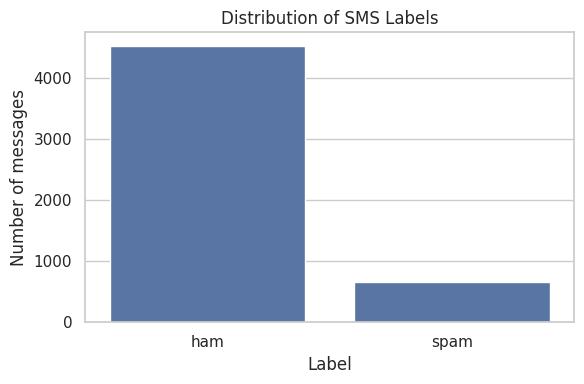

In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="label", order=["ham", "spam"])
plt.title("Distribution of SMS Labels")
plt.xlabel("Label")
plt.ylabel("Number of messages")
plt.tight_layout()
plt.show()

In [6]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_message"] = df["message"].apply(clean_text)
df["target"] = df["label"].map({"ham": 0, "spam": 1})

display(df[["label", "message", "clean_message", "target"]].head())

,label,message,clean_message,target
0,ham,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...,0
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...,1
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...,0


In [7]:
X = df["clean_message"]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training messages: {len(X_train)}")
print(f"Testing messages:  {len(X_test)}")

Training messages: 4135
Testing messages:  1034


In [8]:
models = {
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=1, max_features=10000)),
        ("model", MultinomialNB())
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=1, max_features=10000)),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=1, max_features=10000)),
        ("model", LinearSVC(class_weight="balanced", random_state=RANDOM_STATE))
    ])
}

results = []
fitted_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    fitted_models[name] = model
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False).reset_index(drop=True)
display(results_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1-score": "{:.4f}"
}))

,Model,Accuracy,Precision,Recall,F1-score
0,Linear SVM,0.9836,0.9524,0.9160,0.9339
1,Logistic Regression,0.9749,0.8889,0.9160,0.9023
2,Multinomial Naive Bayes,0.9613,1.0000,0.6947,0.8198


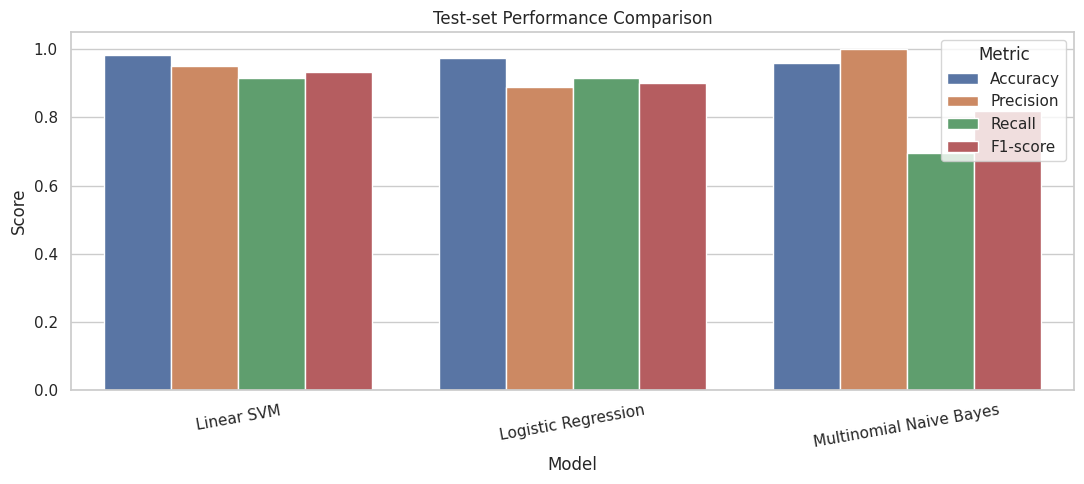

In [9]:
plot_df = results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1-score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 5))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric")
plt.ylim(0, 1.05)
plt.title("Test-set Performance Comparison")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [10]:
svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=1, max_features=10000)),
    ("model", LinearSVC(class_weight="balanced", random_state=RANDOM_STATE))
])

param_grid = {
    "model__C": [0.1, 0.5, 1.0, 2.0, 5.0]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print(f"Best mean CV F1-score: {grid.best_score_:.4f}")
best_svm = grid.best_estimator_

Best parameters: {'model__C': 0.5}
Best mean CV F1-score: 0.9360


Tuned Linear SVM — Test Set
Accuracy:  0.9787
Precision: 0.9160
Recall:    0.9160
F1-score:  0.9160

Classification report:
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       903
        Spam       0.92      0.92      0.92       131

    accuracy                           0.98      1034
   macro avg       0.95      0.95      0.95      1034
weighted avg       0.98      0.98      0.98      1034



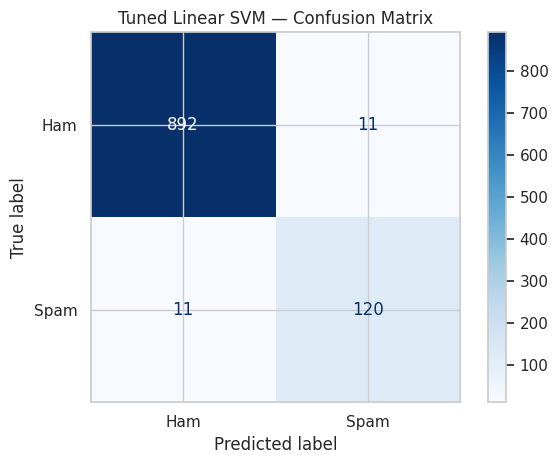

In [11]:
svm_pred = best_svm.predict(X_test)

print("Tuned Linear SVM — Test Set")
print(f"Accuracy:  {accuracy_score(y_test, svm_pred):.4f}")
print(f"Precision: {precision_score(y_test, svm_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, svm_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, svm_pred, zero_division=0):.4f}")
print("\nClassification report:")
print(classification_report(y_test, svm_pred, target_names=["Ham", "Spam"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, svm_pred,
    display_labels=["Ham", "Spam"],
    cmap="Blues",
    values_format="d"
)
plt.title("Tuned Linear SVM — Confusion Matrix")
plt.tight_layout()
plt.show()

In [12]:
cv_scores = cross_val_score(
    best_svm,
    X_train,
    y_train,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

print("Fold F1-scores:", np.round(cv_scores, 4))
print(f"Mean CV F1-score: {cv_scores.mean():.4f}")
print(f"Standard deviation: {cv_scores.std():.4f}")

Fold F1-scores: [0.9314 0.9314 0.9406 0.9479 0.9289]
Mean CV F1-score: 0.9360
Standard deviation: 0.0071


In [13]:
def predict_sms(message):
    cleaned = clean_text(message)
    prediction = best_svm.predict([cleaned])[0]
    return "Spam" if prediction == 1 else "Ham"

examples = [
    "Congratulations! You have won a free iPhone. Click here now.",
    "Hi, are we meeting tomorrow at 3 PM?",
    "URGENT! You have been selected for a cash prize. Call now."
]

for message in examples:
    print(f"Message: {message}")
    print(f"Prediction: {predict_sms(message)}\n")

Message: Congratulations! You have won a free iPhone. Click here now.
Prediction: Spam

Message: Hi, are we meeting tomorrow at 3 PM?
Prediction: Ham

Message: URGENT! You have been selected for a cash prize. Call now.
Prediction: Spam

